# Experiment 6: Unsupervised Learning – Clustering Algorithms

---
### **Aim / Objective:**
To implement K-Means and Hierarchical Agglomerative Clustering, evaluate optimal cluster counts using the Elbow Method and Silhouette Analysis, and visualize dendrograms.

---
### **Theory & Overview:**
Clustering groups unlabeled data points into clusters based on geometric proximity:
- **K-Means**: Minimizes within-cluster sum-of-squares (inertia). Centroids are iteratively updated until convergence.
- **Hierarchical Clustering**: Bottom-up agglomerative grouping using linkage criteria (Ward, Complete, Average).
- **Evaluation**:
  - Inertia (Elbow Curve)
  - Silhouette Score ($s = (b - a)/\max(a, b)$) where $s \in [-1, 1]$.



### **1. Dataset Synthesis for Clustering**


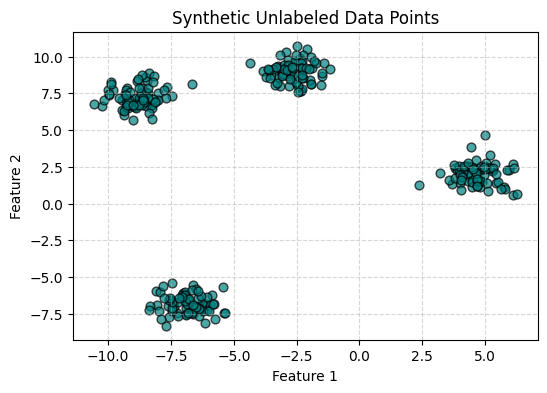

In [ ]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.70, random_state=42)

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], s=40, color='teal', alpha=0.7, edgecolors='k')
plt.title("Synthetic Unlabeled Data Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



### **2. K-Means Clustering & Optimal K Evaluation (Elbow & Silhouette)**


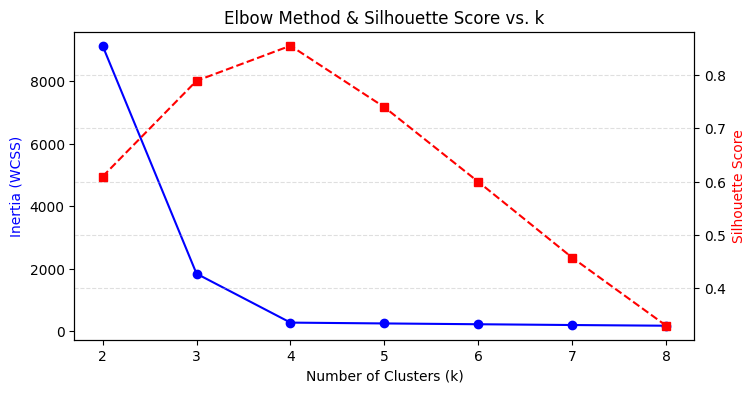

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, kmeans.labels_))

# Plot Elbow and Silhouette curves
fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.plot(k_range, inertias, 'bo-', label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (WCSS)', color='b')

ax2 = ax1.twinx()
ax2.plot(k_range, silhouette_scores, 'rs--', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')

plt.title("Elbow Method & Silhouette Score vs. k")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()



### **3. Optimal K-Means Clustering Visualization**


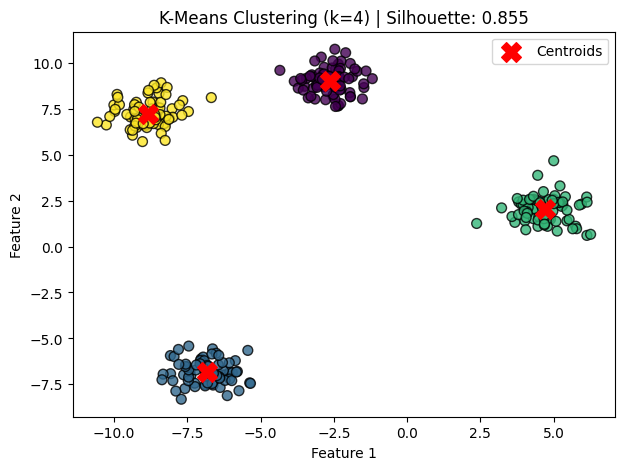

In [ ]:
kmeans_optimal = KMeans(n_clusters=4, random_state=42, n_init=10)
y_kmeans = kmeans_optimal.fit_transform(X)
labels = kmeans_optimal.labels_
centers = kmeans_optimal.cluster_centers_

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis', edgecolors='k', alpha=0.8)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', label='Centroids')
plt.title(f"K-Means Clustering (k=4) | Silhouette: {silhouette_score(X, labels):.3f}")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()



### **4. Hierarchical Clustering & Dendrogram Plotting**


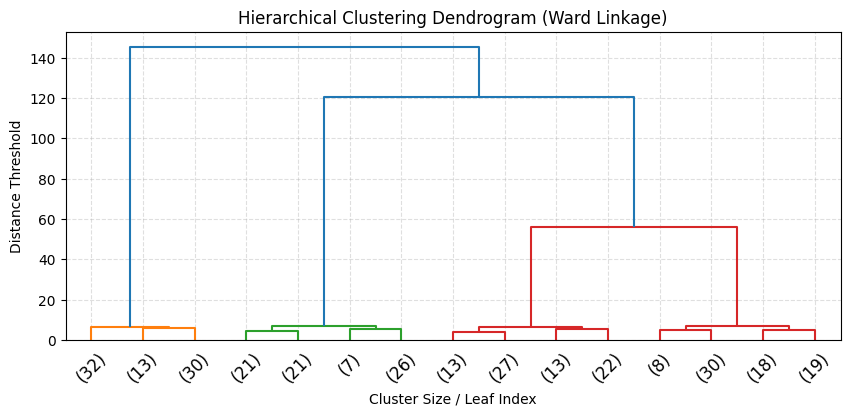

Hierarchical Clustering Silhouette Score: 0.855


In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Generate linkage matrix using Ward's method
linked = linkage(X, method='ward')

plt.figure(figsize=(10, 4))
dendrogram(linked, truncate_mode='lastp', p=15, show_leaf_counts=True, leaf_rotation=45)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Cluster Size / Leaf Index")
plt.ylabel("Distance Threshold")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

# Agglomerative clustering with 4 clusters
agg = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg.fit_predict(X)

print(f"Hierarchical Clustering Silhouette Score: {silhouette_score(X, agg_labels):.3f}")



---
### **Conclusion & Learning Outcomes:**
Applied K-Means and Hierarchical Clustering algorithms to multi-cluster data, systematically determined the optimal cluster count using Elbow and Silhouette analysis, and constructed hierarchical dendrogram structures.
